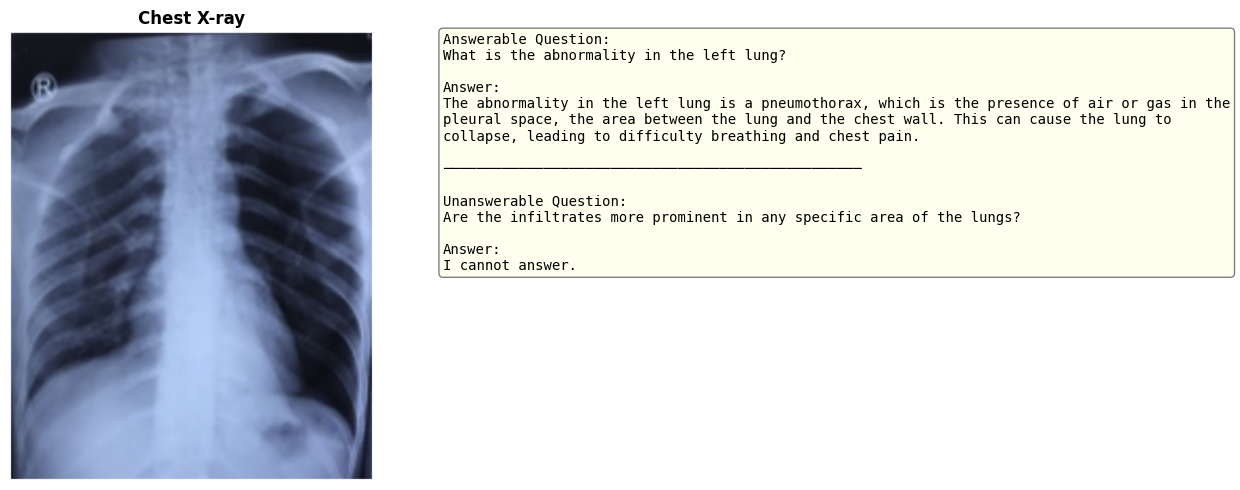

Index: 0
Image: /shared/rc/vlm-idk/LLaVA/data/images/32577372_fig1.jpg


In [2]:
import json
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from PIL import Image

VAL_FILE = "/home/as5606/projects/Super_LlaVA_Med/dataset/x_ray/open_ended_train_and_val/val_open_ended_annotations.jsonl"

records = [json.loads(l) for l in open(VAL_FILE)]

# Find a pair with same index (standard + upd)
standard = {r["index"]: r for r in records if r["type"] == "standard"}
upd      = {r["index"]: r for r in records if r["type"] == "upd"}
shared_indices = set(standard.keys()) & set(upd.keys())

# Pick the first shared index
idx = next(iter(shared_indices))
std_rec = standard[idx]
upd_rec = upd[idx]

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: image
img = Image.open(std_rec["image_path"]).convert("RGB")
axes[0].imshow(img)
axes[0].axis("off")
axes[0].set_title("Chest X-ray", fontsize=12, fontweight="bold")

# Right: text
text = (
    f"Answerable Question:\n{std_rec['question']}\n\n"
    f"Answer:\n{std_rec['answer'][:300]}\n\n"
    f"{'─'*50}\n\n"
    f"Unanswerable Question:\n{upd_rec['question']}\n\n"
    f"Answer:\n{upd_rec['answer']}"
)
axes[1].axis("off")
axes[1].text(0, 1, text, transform=axes[1].transAxes,
             fontsize=10, verticalalignment="top",
             wrap=True, family="monospace",
             bbox=dict(boxstyle="round", facecolor="lightyellow", alpha=0.5))

plt.tight_layout()
plt.savefig("paper_example_xray.pdf", bbox_inches="tight")
plt.show()
print(f"Index: {idx}")
print(f"Image: {std_rec['image_path']}")


Original image: /shared/rc/vlm-idk/LLaVA/data/images/32798215_f1-amjcaserep-21-e925787.jpg


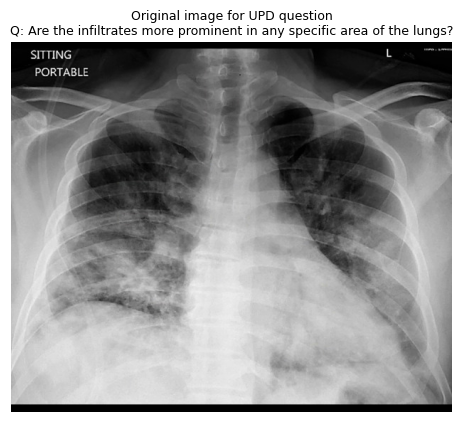

In [4]:
target_q = "Are the infiltrates more prominent in any specific area of the lungs?"

match = next((r for r in records if r["type"] == "standard" and r["question"] == target_q), None)

if match:
    print(f"Original image: {match['image_path']}")
    img = Image.open(match["image_path"]).convert("RGB")
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"Original image for UPD question\nQ: {target_q}", fontsize=9)
    plt.show()
else:
    print("Not found in val set — might be in train set")


Index: 0
Test image:   /shared/rc/vlm-idk/LLaVA/data/images/32577372_fig1.jpg
Source image: /shared/rc/vlm-idk/LLaVA/data/images/32798215_f1-amjcaserep-21-e925787.jpg
Answerable Q:   What is the abnormality in the left lung?
Unanswerable Q: Are the infiltrates more prominent in any specific area of the lungs?


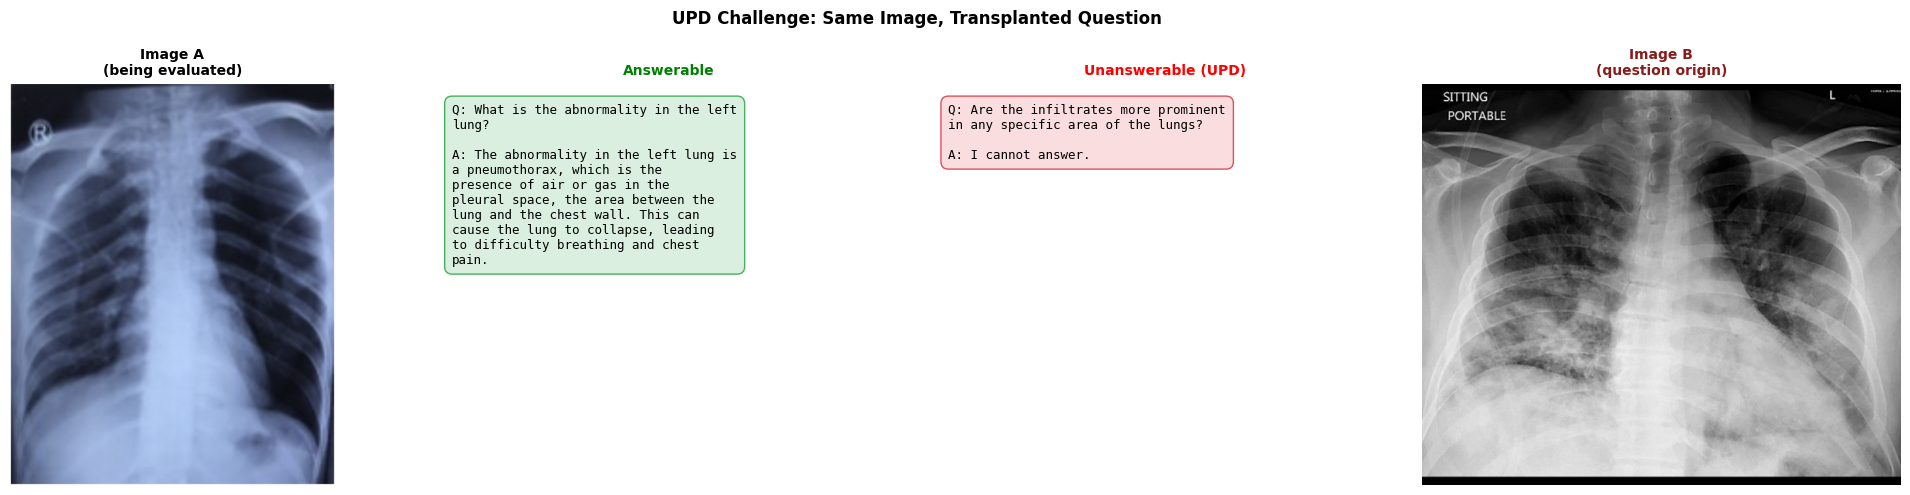

In [5]:
import json
import matplotlib.pyplot as plt
from PIL import Image
import textwrap

VAL_FILE = "/home/as5606/projects/Super_LlaVA_Med/dataset/x_ray/open_ended_train_and_val/val_open_ended_annotations.jsonl"
TRAIN_FILE = "/home/as5606/projects/Super_LlaVA_Med/dataset/x_ray/open_ended_train_and_val/train_open_ended_annotations.jsonl"

records = [json.loads(l) for l in open(VAL_FILE)]
train_records = [json.loads(l) for l in open(TRAIN_FILE)]
all_records = records + train_records

standard = {r["index"]: r for r in records if r["type"] == "standard"}
upd      = {r["index"]: r for r in records if r["type"] == "upd"}
shared_indices = sorted(set(standard.keys()) & set(upd.keys()))

# Find a pair where source image is also findable
for idx in shared_indices:
    std_rec = standard[idx]
    upd_rec = upd[idx]
    source_rec = next((r for r in all_records if r["type"] == "standard" and r["question"] == upd_rec["question"]), None)
    if source_rec and source_rec["image_path"] != std_rec["image_path"]:
        break

print(f"Index: {idx}")
print(f"Test image:   {std_rec['image_path']}")
print(f"Source image: {source_rec['image_path']}")
print(f"Answerable Q:   {std_rec['question']}")
print(f"Unanswerable Q: {upd_rec['question']}")

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

# Panel 1: Test image
img_a = Image.open(std_rec["image_path"]).convert("RGB")
axes[0].imshow(img_a)
axes[0].axis("off")
axes[0].set_title("Image A\n(being evaluated)", fontsize=10, fontweight="bold")

# Panel 2: Answerable Q&A
axes[1].axis("off")
axes[1].set_title("Answerable", fontsize=10, fontweight="bold", color="green")
q1 = "\n".join(textwrap.wrap(std_rec["question"], 35))
a1 = "\n".join(textwrap.wrap(std_rec["answer"][:250], 35))
axes[1].text(0.05, 0.95, f"Q: {q1}\n\nA: {a1}",
    transform=axes[1].transAxes, fontsize=9, verticalalignment="top", family="monospace",
    bbox=dict(boxstyle="round,pad=0.6", facecolor="#d4edda", edgecolor="#28a745", alpha=0.85))

# Panel 3: Unanswerable Q&A
axes[2].axis("off")
axes[2].set_title("Unanswerable (UPD)", fontsize=10, fontweight="bold", color="red")
q2 = "\n".join(textwrap.wrap(upd_rec["question"], 35))
axes[2].text(0.05, 0.95, f"Q: {q2}\n\nA: I cannot answer.",
    transform=axes[2].transAxes, fontsize=9, verticalalignment="top", family="monospace",
    bbox=dict(boxstyle="round,pad=0.6", facecolor="#f8d7da", edgecolor="#dc3545", alpha=0.85))

# Panel 4: Source image (where the UPD question came from)
img_b = Image.open(source_rec["image_path"]).convert("RGB")
axes[3].imshow(img_b)
axes[3].axis("off")
axes[3].set_title("Image B\n(question origin)", fontsize=10, fontweight="bold", color="#8b1a1a")

plt.suptitle("UPD Challenge: Same Image, Transplanted Question", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("/home/as5606/projects/Super_LlaVA_Med/paper_graphs/paper_example_xray.pdf", bbox_inches="tight", dpi=150)
plt.show()


In [6]:
import os
import shutil

os.makedirs("/home/as5606/projects/Super_LlaVA_Med/image_download", exist_ok=True)

shutil.copy(std_rec["image_path"],    "/home/as5606/projects/Super_LlaVA_Med/image_download/image_A_test.jpg")
shutil.copy(source_rec["image_path"], "/home/as5606/projects/Super_LlaVA_Med/image_download/image_B_source.jpg")

print("Saved:")
print("  image_A_test.jpg   →", std_rec["image_path"])
print("  image_B_source.jpg →", source_rec["image_path"])


Saved:
  image_A_test.jpg   → /shared/rc/vlm-idk/LLaVA/data/images/32577372_fig1.jpg
  image_B_source.jpg → /shared/rc/vlm-idk/LLaVA/data/images/32798215_f1-amjcaserep-21-e925787.jpg


Index: 0
Test image:   /shared/rc/vlm-idk/LLaVA/data/images/29507846_FIG1.jpg
Source image: /shared/rc/vlm-idk/LLaVA/data/images/29382812_f2-amjcaserep-19-114.jpg
Answerable Q:   What is the location of the tumor?
Unanswerable Q: What type of MRI sequence is used?


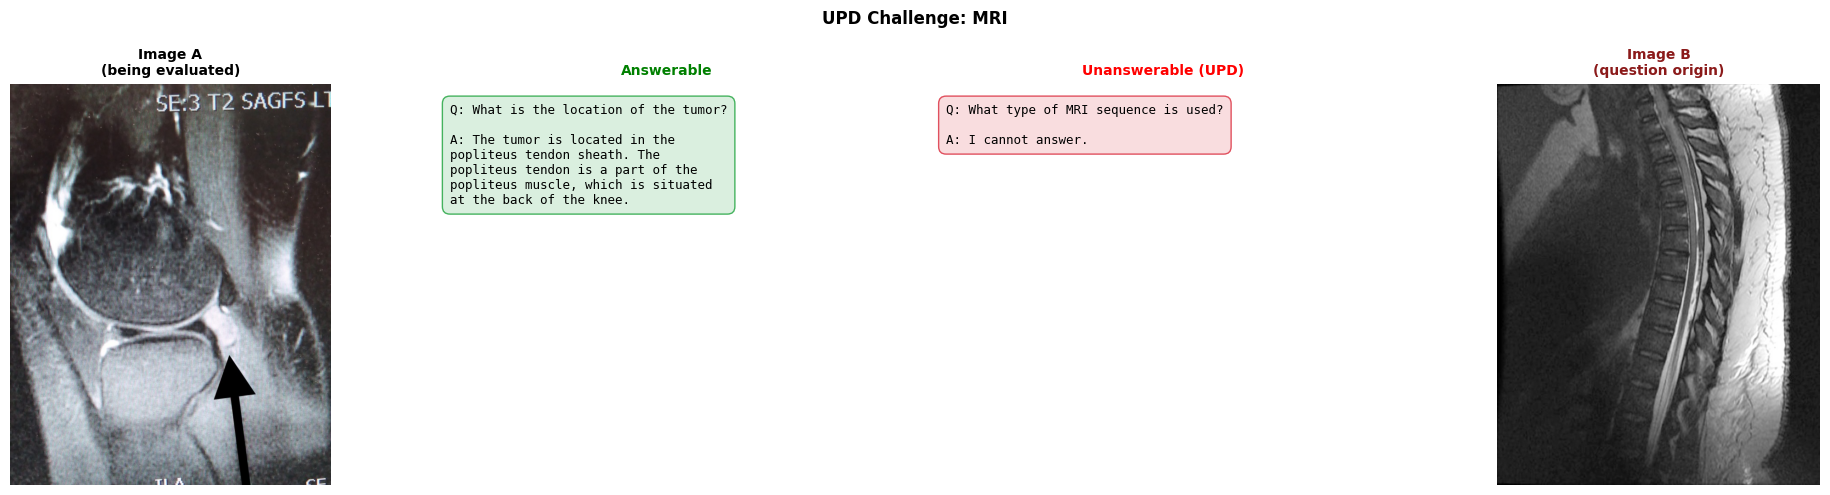

Images saved to image_download/


In [7]:
import json
import matplotlib.pyplot as plt
from PIL import Image
import textwrap
import os
import shutil

VAL_FILE   = "/home/as5606/projects/Super_LlaVA_Med/dataset/MRI/open_ended_train_and_val/val_open_ended_annotations.jsonl"
TRAIN_FILE = "/home/as5606/projects/Super_LlaVA_Med/dataset/MRI/open_ended_train_and_val/train_open_ended_annotations.jsonl"

records       = [json.loads(l) for l in open(VAL_FILE)]
train_records = [json.loads(l) for l in open(TRAIN_FILE)]
all_records   = records + train_records

standard = {r["index"]: r for r in records if r["type"] == "standard"}
upd      = {r["index"]: r for r in records if r["type"] == "upd"}
shared_indices = sorted(set(standard.keys()) & set(upd.keys()))

# Find a pair where source image is findable and different
for idx in shared_indices:
    std_rec    = standard[idx]
    upd_rec    = upd[idx]
    source_rec = next((r for r in all_records if r["type"] == "standard" and r["question"] == upd_rec["question"]), None)
    if source_rec and source_rec["image_path"] != std_rec["image_path"]:
        break

print(f"Index: {idx}")
print(f"Test image:   {std_rec['image_path']}")
print(f"Source image: {source_rec['image_path']}")
print(f"Answerable Q:   {std_rec['question']}")
print(f"Unanswerable Q: {upd_rec['question']}")

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

img_a = Image.open(std_rec["image_path"]).convert("RGB")
axes[0].imshow(img_a)
axes[0].axis("off")
axes[0].set_title("Image A\n(being evaluated)", fontsize=10, fontweight="bold")

axes[1].axis("off")
axes[1].set_title("Answerable", fontsize=10, fontweight="bold", color="green")
q1 = "\n".join(textwrap.wrap(std_rec["question"], 35))
a1 = "\n".join(textwrap.wrap(std_rec["answer"][:250], 35))
axes[1].text(0.05, 0.95, f"Q: {q1}\n\nA: {a1}",
    transform=axes[1].transAxes, fontsize=9, verticalalignment="top", family="monospace",
    bbox=dict(boxstyle="round,pad=0.6", facecolor="#d4edda", edgecolor="#28a745", alpha=0.85))

axes[2].axis("off")
axes[2].set_title("Unanswerable (UPD)", fontsize=10, fontweight="bold", color="red")
q2 = "\n".join(textwrap.wrap(upd_rec["question"], 35))
axes[2].text(0.05, 0.95, f"Q: {q2}\n\nA: I cannot answer.",
    transform=axes[2].transAxes, fontsize=9, verticalalignment="top", family="monospace",
    bbox=dict(boxstyle="round,pad=0.6", facecolor="#f8d7da", edgecolor="#dc3545", alpha=0.85))

img_b = Image.open(source_rec["image_path"]).convert("RGB")
axes[3].imshow(img_b)
axes[3].axis("off")
axes[3].set_title("Image B\n(question origin)", fontsize=10, fontweight="bold", color="#8b1a1a")

plt.suptitle("UPD Challenge: MRI", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("/home/as5606/projects/Super_LlaVA_Med/paper_graphs/paper_example_mri.pdf", bbox_inches="tight", dpi=150)
plt.show()

# Save the two images
os.makedirs("/home/as5606/projects/Super_LlaVA_Med/image_download", exist_ok=True)
shutil.copy(std_rec["image_path"],    "/home/as5606/projects/Super_LlaVA_Med/image_download/mri_image_A_test.jpg")
shutil.copy(source_rec["image_path"], "/home/as5606/projects/Super_LlaVA_Med/image_download/mri_image_B_source.jpg")
print("Images saved to image_download/")


In [8]:
# Skip first match, look for a better example
good_pairs = []
for idx in shared_indices:
    std_rec    = standard[idx]
    upd_rec    = upd[idx]
    source_rec = next((r for r in all_records if r["type"] == "standard" and r["question"] == upd_rec["question"]), None)
    if source_rec and source_rec["image_path"] != std_rec["image_path"]:
        good_pairs.append((idx, std_rec, upd_rec, source_rec))

# Print first 5 so you can pick a clean one
for idx, s, u, src in good_pairs[:5]:
    print(f"idx={idx}")
    print(f"  Answerable Q:   {s['question']}")
    print(f"  Unanswerable Q: {u['question']}")
    print()


idx=0
  Answerable Q:   What is the location of the tumor?
  Unanswerable Q: What type of MRI sequence is used?

idx=1
  Answerable Q:   What is the size of the mass?
  Unanswerable Q: How many slices are shown in each panel?

idx=2
  Answerable Q:   What does the short arrow point to?
  Unanswerable Q: What do the red arrows represent?

idx=3
  Answerable Q:   What are the characteristics of the tumor in the image?
  Unanswerable Q: What are the findings in the pre-frontal area?

idx=4
  Answerable Q:   What is the size of the fracture?
  Unanswerable Q: What does the MR venography show?



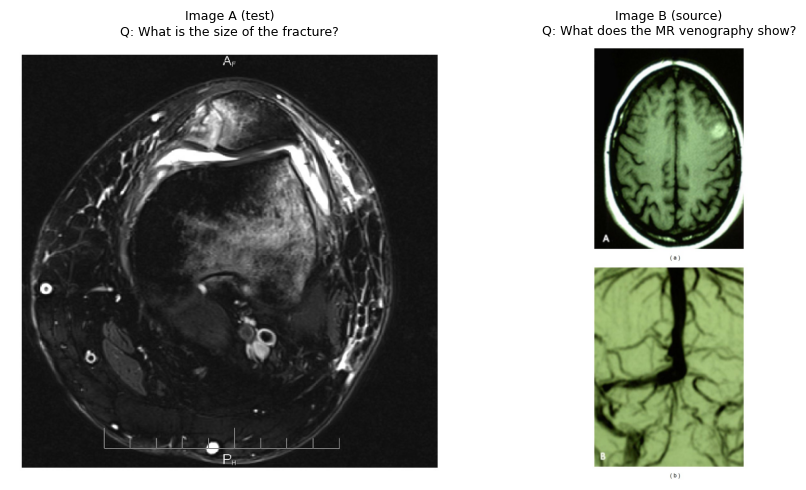

In [12]:
idx = 4
std_rec    = standard[idx]
upd_rec    = upd[idx]
source_rec = next((r for r in all_records if r["type"] == "standard" and r["question"] == upd_rec["question"]), None)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

img_a = Image.open(std_rec["image_path"]).convert("RGB")
axes[0].imshow(img_a)
axes[0].axis("off")
axes[0].set_title(f"Image A (test)\nQ: {std_rec['question']}", fontsize=9)

img_b = Image.open(source_rec["image_path"]).convert("RGB")
axes[1].imshow(img_b)
axes[1].axis("off")
axes[1].set_title(f"Image B (source)\nQ: {upd_rec['question']}", fontsize=9)

plt.tight_layout()
plt.show()

In [13]:
import shutil, os

os.makedirs("/home/as5606/projects/Super_LlaVA_Med/image_download", exist_ok=True)

shutil.copy(std_rec["image_path"],    "/home/as5606/projects/Super_LlaVA_Med/image_download/mri_image_A_test.jpg")
shutil.copy(source_rec["image_path"], "/home/as5606/projects/Super_LlaVA_Med/image_download/mri_image_B_source.jpg")

print("Saved!")
print("  mri_image_A_test.jpg   →", std_rec["image_path"])
print("  mri_image_B_source.jpg →", source_rec["image_path"])


Saved!
  mri_image_A_test.jpg   → /shared/rc/vlm-idk/LLaVA/data/images/27840644_fig2.jpg
  mri_image_B_source.jpg → /shared/rc/vlm-idk/LLaVA/data/images/23424596_fig1.jpg


In [14]:
import json
import matplotlib.pyplot as plt
from PIL import Image
import textwrap
import os, shutil

VAL_FILE   = "/home/as5606/projects/Super_LlaVA_Med/dataset/CT/open_ended_train_and_val/val_open_ended_annotations.jsonl"
TRAIN_FILE = "/home/as5606/projects/Super_LlaVA_Med/dataset/CT/open_ended_train_and_val/train_open_ended_annotations.jsonl"

records       = [json.loads(l) for l in open(VAL_FILE)]
train_records = [json.loads(l) for l in open(TRAIN_FILE)]
all_records   = records + train_records

standard = {r["index"]: r for r in records if r["type"] == "standard"}
upd      = {r["index"]: r for r in records if r["type"] == "upd"}
shared_indices = sorted(set(standard.keys()) & set(upd.keys()))

good_pairs = []
for idx in shared_indices:
    std_rec    = standard[idx]
    upd_rec    = upd[idx]
    source_rec = next((r for r in all_records if r["type"] == "standard" and r["question"] == upd_rec["question"]), None)
    if source_rec and source_rec["image_path"] != std_rec["image_path"]:
        good_pairs.append((idx, std_rec, upd_rec, source_rec))

for idx, s, u, src in good_pairs[:10]:
    print(f"idx={idx}")
    print(f"  Answerable Q:   {s['question']}")
    print(f"  Unanswerable Q: {u['question']}")
    print()


idx=0
  Answerable Q:   What are the black arrows pointing to in images (a) and (b)?
  Unanswerable Q: What is the mass affecting?

idx=1
  Answerable Q:   What do the arrows point to?
  Unanswerable Q: What is the relationship between the spleen and the colon in this image?

idx=2
  Answerable Q:   What is the main difference between the right and left side in the image?
  Unanswerable Q: What is the long arrow pointing to?

idx=3
  Answerable Q:   Which bone is affected?
  Unanswerable Q: What is the black arrow pointing to?

idx=4
  Answerable Q:   What part of the brain is affected?
  Unanswerable Q: Where is the nodule located?

idx=5
  Answerable Q:   What is the size of the cystic lesion?
  Unanswerable Q: What is the abnormality in the descending aorta?

idx=6
  Answerable Q:   What is the shape of the tumor?
  Unanswerable Q: What are the yellow arrows pointing to?

idx=7
  Answerable Q:   What is the suspected fracture in the image?
  Unanswerable Q: What do the thin arrows i

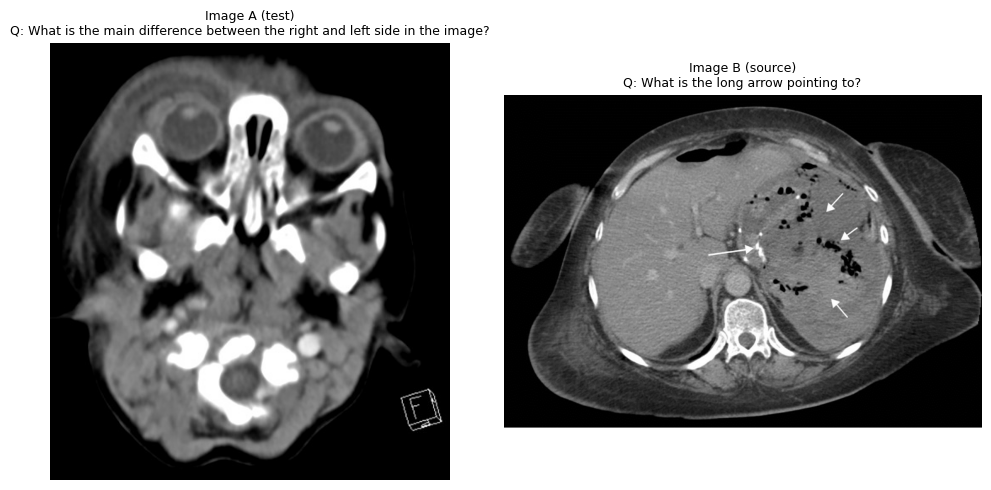

In [15]:
idx = 2
std_rec    = standard[idx]
upd_rec    = upd[idx]
source_rec = next((r for r in all_records if r["type"] == "standard" and r["question"] == upd_rec["question"]), None)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

img_a = Image.open(std_rec["image_path"]).convert("RGB")
axes[0].imshow(img_a)
axes[0].axis("off")
axes[0].set_title(f"Image A (test)\nQ: {std_rec['question']}", fontsize=9)

img_b = Image.open(source_rec["image_path"]).convert("RGB")
axes[1].imshow(img_b)
axes[1].axis("off")
axes[1].set_title(f"Image B (source)\nQ: {upd_rec['question']}", fontsize=9)

plt.tight_layout()
plt.show()


In [16]:
os.makedirs("/home/as5606/projects/Super_LlaVA_Med/image_download", exist_ok=True)

shutil.copy(std_rec["image_path"],    "/home/as5606/projects/Super_LlaVA_Med/image_download/ct_image_A_test.jpg")
shutil.copy(source_rec["image_path"], "/home/as5606/projects/Super_LlaVA_Med/image_download/ct_image_B_source.jpg")

print("Saved!")
print("  ct_image_A_test.jpg   →", std_rec["image_path"])
print("  ct_image_B_source.jpg →", source_rec["image_path"])


Saved!
  ct_image_A_test.jpg   → /shared/rc/vlm-idk/LLaVA/data/images/31293873_F2.jpg
  ct_image_B_source.jpg → /shared/rc/vlm-idk/LLaVA/data/images/21655117_F4.jpg


In [17]:
import json
import matplotlib.pyplot as plt
from PIL import Image
import os, shutil

VAL_FILE   = "/home/as5606/projects/Super_LlaVA_Med/dataset/histology/open_ended_train_and_val/val_open_ended_annotations.jsonl"
TRAIN_FILE = "/home/as5606/projects/Super_LlaVA_Med/dataset/histology/open_ended_train_and_val/train_open_ended_annotations.jsonl"

records       = [json.loads(l) for l in open(VAL_FILE)]
train_records = [json.loads(l) for l in open(TRAIN_FILE)]
all_records   = records + train_records

standard = {r["index"]: r for r in records if r["type"] == "standard"}
upd      = {r["index"]: r for r in records if r["type"] == "upd"}
shared_indices = sorted(set(standard.keys()) & set(upd.keys()))

good_pairs = []
for idx in shared_indices:
    std_rec    = standard[idx]
    upd_rec    = upd[idx]
    source_rec = next((r for r in all_records if r["type"] == "standard" and r["question"] == upd_rec["question"]), None)
    if source_rec and source_rec["image_path"] != std_rec["image_path"]:
        good_pairs.append((idx, std_rec, upd_rec, source_rec))

for idx, s, u, src in good_pairs[:10]:
    print(f"idx={idx}")
    print(f"  Answerable Q:   {s['question']}")
    print(f"  Unanswerable Q: {u['question']}")
    print()


idx=0
  Answerable Q:   What type of glands are shown in the image?
  Unanswerable Q: What type of staining is used in the image?

idx=1
  Answerable Q:   What is the staining technique used?
  Unanswerable Q: What does the absence of red signal in the defect center suggest?

idx=2
  Answerable Q:   What is the staining technique used?
  Unanswerable Q: What is the imaging technique used in this figure?

idx=3
  Answerable Q:   What type of tissue is shown in the image?
  Unanswerable Q: What type of stain is used in the image?

idx=4
  Answerable Q:   What are the black arrows pointing to?
  Unanswerable Q: What is the staining technique used?

idx=5
  Answerable Q:   What type of staining is used?
  Unanswerable Q: What is the magnification level of the histological image?

idx=6
  Answerable Q:   What type of staining is used?
  Unanswerable Q: What is the staining technique used?

idx=7
  Answerable Q:   What are the findings in the MF10 section?
  Unanswerable Q: What are the blue

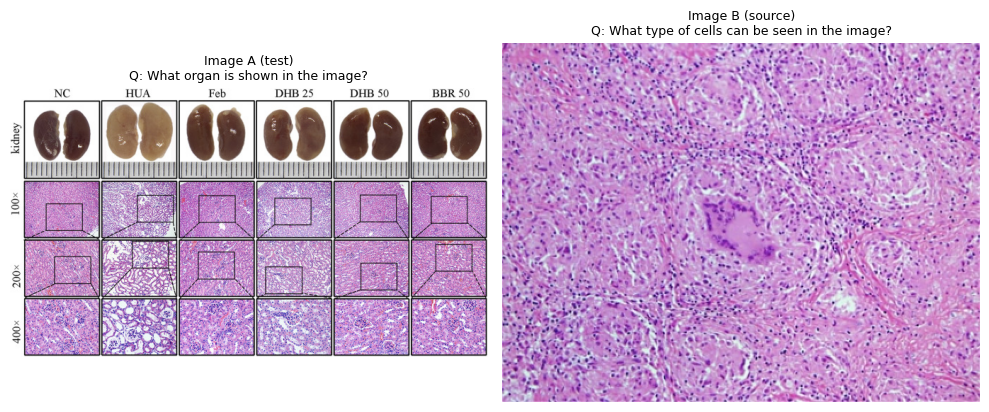

In [18]:
idx = 9
std_rec    = standard[idx]
upd_rec    = upd[idx]
source_rec = next((r for r in all_records if r["type"] == "standard" and r["question"] == upd_rec["question"]), None)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

img_a = Image.open(std_rec["image_path"]).convert("RGB")
axes[0].imshow(img_a)
axes[0].axis("off")
axes[0].set_title(f"Image A (test)\nQ: {std_rec['question']}", fontsize=9)

img_b = Image.open(source_rec["image_path"]).convert("RGB")
axes[1].imshow(img_b)
axes[1].axis("off")
axes[1].set_title(f"Image B (source)\nQ: {upd_rec['question']}", fontsize=9)

plt.tight_layout()
plt.show()


In [19]:
for idx, s, u, src in good_pairs:
    q = u["question"].lower()
    if any(kw in q for kw in ["fluorescen", "inset", "arrow", "green", "red channel", "immunofluor"]):
        print(f"idx={idx}")
        print(f"  Answerable Q:   {s['question']}")
        print(f"  Unanswerable Q: {u['question']}")
        print()


idx=7
  Answerable Q:   What are the findings in the MF10 section?
  Unanswerable Q: What are the blue arrows pointing to?

idx=19
  Answerable Q:   What are the two types of staining used in the image?
  Unanswerable Q: What do the yellow arrows point to?

idx=27
  Answerable Q:   What is the magnification level?
  Unanswerable Q: What do the pink arrows indicate?

idx=30
  Answerable Q:   What is the staining technique used?
  Unanswerable Q: What are the arrows and dotted arrows indicating?

idx=32
  Answerable Q:   What is the stain used in the image?
  Unanswerable Q: What is the purpose of the arrows and arrowheads?

idx=45
  Answerable Q:   What is the staining technique used in the image?
  Unanswerable Q: What do the arrows point to?

idx=46
  Answerable Q:   What is the staining technique used in the image?
  Unanswerable Q: What are the solid arrows pointing to in the liver?

idx=67
  Answerable Q:   What is the staining technique used?
  Unanswerable Q: What is the arrow po

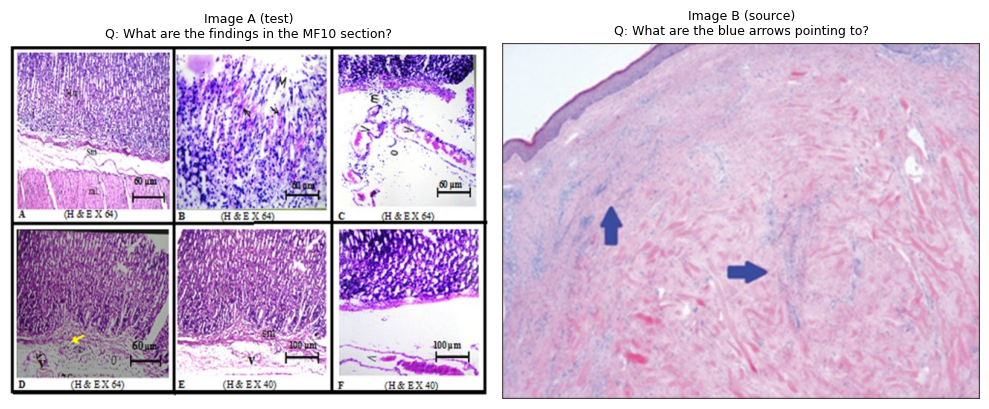

In [20]:
idx = 7
std_rec    = standard[idx]
upd_rec    = upd[idx]
source_rec = next((r for r in all_records if r["type"] == "standard" and r["question"] == upd_rec["question"]), None)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

img_a = Image.open(std_rec["image_path"]).convert("RGB")
axes[0].imshow(img_a)
axes[0].axis("off")
axes[0].set_title(f"Image A (test)\nQ: {std_rec['question']}", fontsize=9)

img_b = Image.open(source_rec["image_path"]).convert("RGB")
axes[1].imshow(img_b)
axes[1].axis("off")
axes[1].set_title(f"Image B (source)\nQ: {upd_rec['question']}", fontsize=9)

plt.tight_layout()
plt.show()


In [21]:
os.makedirs("/home/as5606/projects/Super_LlaVA_Med/image_download", exist_ok=True)

shutil.copy(std_rec["image_path"],    "/home/as5606/projects/Super_LlaVA_Med/image_download/histology_image_A_test.jpg")
shutil.copy(source_rec["image_path"], "/home/as5606/projects/Super_LlaVA_Med/image_download/histology_image_B_source.jpg")

print("Saved!")
print("  histology_image_A_test.jpg   →", std_rec["image_path"])
print("  histology_image_B_source.jpg →", source_rec["image_path"])


Saved!
  histology_image_A_test.jpg   → /shared/rc/vlm-idk/LLaVA/data/images/26196679_pone.0132497.g002.jpg
  histology_image_B_source.jpg → /shared/rc/vlm-idk/LLaVA/data/images/28913244_F1.jpg


In [22]:
import json
import matplotlib.pyplot as plt
from PIL import Image
import os, shutil

VAL_FILE   = "/home/as5606/projects/Super_LlaVA_Med/dataset/gross_pathology/open_ended_train_and_val/val_open_ended_annotations.jsonl"
TRAIN_FILE = "/home/as5606/projects/Super_LlaVA_Med/dataset/gross_pathology/open_ended_train_and_val/train_open_ended_annotations.jsonl"

records       = [json.loads(l) for l in open(VAL_FILE)]
train_records = [json.loads(l) for l in open(TRAIN_FILE)]
all_records   = records + train_records

standard = {r["index"]: r for r in records if r["type"] == "standard"}
upd      = {r["index"]: r for r in records if r["type"] == "upd"}
shared_indices = sorted(set(standard.keys()) & set(upd.keys()))

good_pairs = []
for idx in shared_indices:
    std_rec    = standard[idx]
    upd_rec    = upd[idx]
    source_rec = next((r for r in all_records if r["type"] == "standard" and r["question"] == upd_rec["question"]), None)
    if source_rec and source_rec["image_path"] != std_rec["image_path"]:
        good_pairs.append((idx, std_rec, upd_rec, source_rec))

for idx, s, u, src in good_pairs[:10]:
    print(f"idx={idx}")
    print(f"  Answerable Q:   {s['question']}")
    print(f"  Unanswerable Q: {u['question']}")
    print()


idx=0
  Answerable Q:   Where is the tumor located?
  Unanswerable Q: What does the arrowhead show?

idx=1
  Answerable Q:   Where was the gallstone found?
  Unanswerable Q: What is the color of the heart?

idx=2
  Answerable Q:   What is the appearance of the exterior surface of the specimen?
  Unanswerable Q: What is the organ shown in the image?

idx=3
  Answerable Q:   What is the size of the mass?
  Unanswerable Q: What is the appearance of the cortical surface?

idx=4
  Answerable Q:   What is the object in the fallopian tube?
  Unanswerable Q: Which organ is the lesion found in?

idx=5
  Answerable Q:   What is the appearance of the brain in the image?
  Unanswerable Q: What is the size of the spiculated tumor?

idx=6
  Answerable Q:   What do the solid line circles represent?
  Unanswerable Q: What is the size of the specimen?

idx=7
  Answerable Q:   What is the color of the gross specimen?
  Unanswerable Q: What can you say about the cyst wall?

idx=8
  Answerable Q:   What i

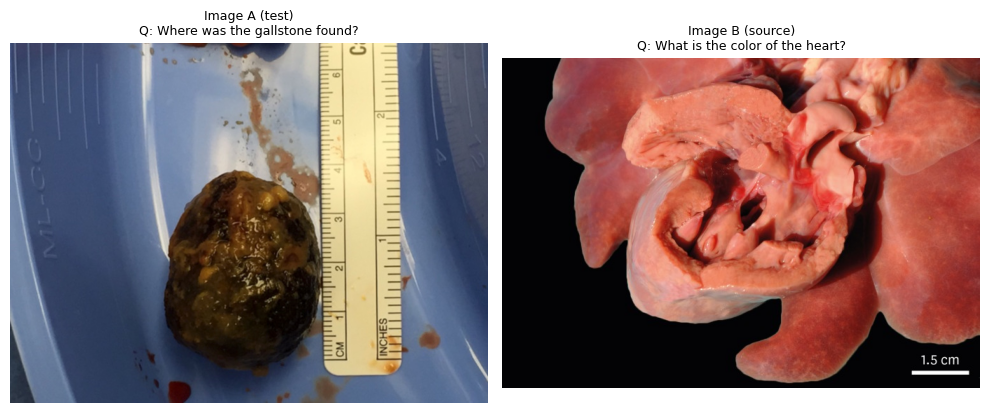

In [23]:
idx = 1
std_rec    = standard[idx]
upd_rec    = upd[idx]
source_rec = next((r for r in all_records if r["type"] == "standard" and r["question"] == upd_rec["question"]), None)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

img_a = Image.open(std_rec["image_path"]).convert("RGB")
axes[0].imshow(img_a)
axes[0].axis("off")
axes[0].set_title(f"Image A (test)\nQ: {std_rec['question']}", fontsize=9)

img_b = Image.open(source_rec["image_path"]).convert("RGB")
axes[1].imshow(img_b)
axes[1].axis("off")
axes[1].set_title(f"Image B (source)\nQ: {upd_rec['question']}", fontsize=9)

plt.tight_layout()
plt.show()


In [24]:
os.makedirs("/home/as5606/projects/Super_LlaVA_Med/image_download", exist_ok=True)

shutil.copy(std_rec["image_path"],    "/home/as5606/projects/Super_LlaVA_Med/image_download/pathology_image_A_test.jpg")
shutil.copy(source_rec["image_path"], "/home/as5606/projects/Super_LlaVA_Med/image_download/pathology_image_B_source.jpg")

print("Saved!")
print("  pathology_image_A_test.jpg   →", std_rec["image_path"])
print("  pathology_image_B_source.jpg →", source_rec["image_path"])


Saved!
  pathology_image_A_test.jpg   → /shared/rc/vlm-idk/LLaVA/data/images/33907633_FIG3.jpg
  pathology_image_B_source.jpg → /shared/rc/vlm-idk/LLaVA/data/images/31565895_F3.jpg


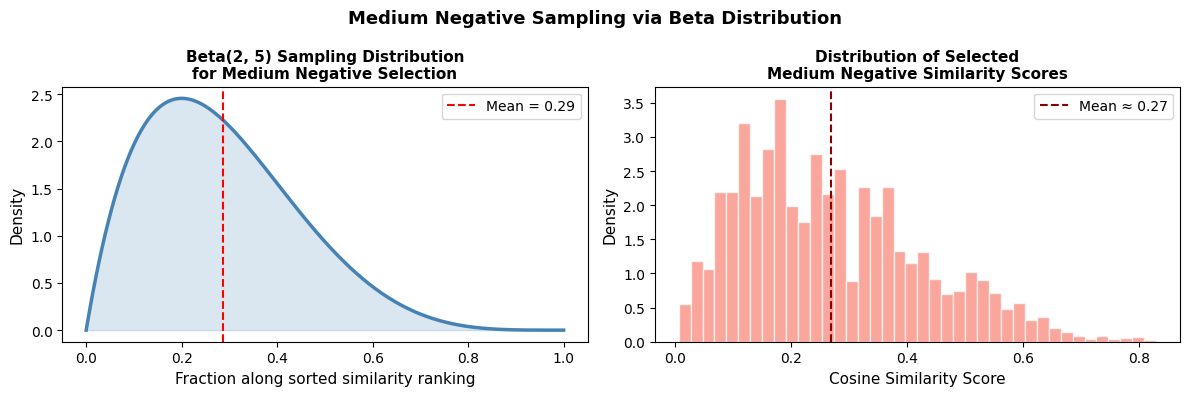

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# --- Left: Beta(2,5) sampling distribution ---
x = np.linspace(0, 1, 300)
ax = axes[0]
ax.plot(x, beta.pdf(x, 2, 5), color='steelblue', linewidth=2.5)
ax.fill_between(x, beta.pdf(x, 2, 5), alpha=0.2, color='steelblue')
ax.axvline(x=beta.mean(2, 5), color='red', linestyle='--', linewidth=1.5, label=f'Mean = {beta.mean(2,5):.2f}')
ax.set_xlabel("Fraction along sorted similarity ranking", fontsize=11)
ax.set_ylabel("Density", fontsize=11)
ax.set_title("Beta(2, 5) Sampling Distribution\nfor Medium Negative Selection", fontsize=11, fontweight='bold')
ax.legend(fontsize=10)

# --- Right: What it means in terms of cosine similarity ---
# Simulate: sort sims, pick index via beta(2,5)
N = 1000
np.random.seed(42)
sim_scores = np.sort(np.random.uniform(0, 1, N))  # sorted similarities
fracs = np.random.beta(2, 5, size=5000)
sampled_sims = sim_scores[(fracs * (N - 1)).astype(int)]

ax2 = axes[1]
ax2.hist(sampled_sims, bins=40, density=True, color='salmon', alpha=0.7, edgecolor='white')
ax2.set_xlabel("Cosine Similarity Score", fontsize=11)
ax2.set_ylabel("Density", fontsize=11)
ax2.set_title("Distribution of Selected\nMedium Negative Similarity Scores", fontsize=11, fontweight='bold')
ax2.axvline(sampled_sims.mean(), color='darkred', linestyle='--', linewidth=1.5, label=f'Mean ≈ {sampled_sims.mean():.2f}')
ax2.legend(fontsize=10)

plt.suptitle("Medium Negative Sampling via Beta Distribution", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("/home/as5606/projects/Super_LlaVA_Med/paper_graphs/beta_sampling.pdf", bbox_inches="tight", dpi=150)
plt.show()


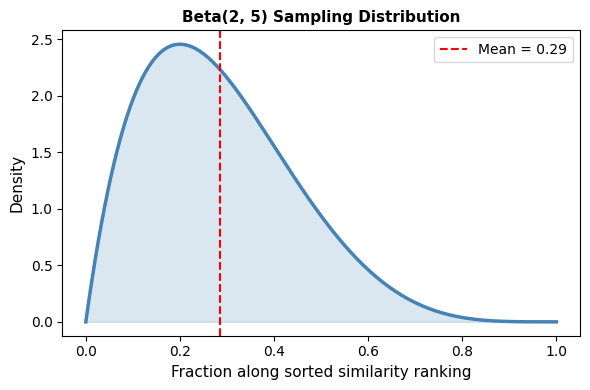

Saved!


In [26]:
fig, ax = plt.subplots(figsize=(6, 4))

x = np.linspace(0, 1, 300)
ax.plot(x, beta.pdf(x, 2, 5), color='steelblue', linewidth=2.5)
ax.fill_between(x, beta.pdf(x, 2, 5), alpha=0.2, color='steelblue')
ax.axvline(x=beta.mean(2, 5), color='red', linestyle='--', linewidth=1.5, label=f'Mean = {beta.mean(2,5):.2f}')
ax.set_xlabel("Fraction along sorted similarity ranking", fontsize=11)
ax.set_ylabel("Density", fontsize=11)
ax.set_title("Beta(2, 5) Sampling Distribution", fontsize=11, fontweight='bold')
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig("/home/as5606/projects/Super_LlaVA_Med/paper_graphs/beta_distribution.pdf", bbox_inches="tight", dpi=150)
plt.show()
print("Saved!")

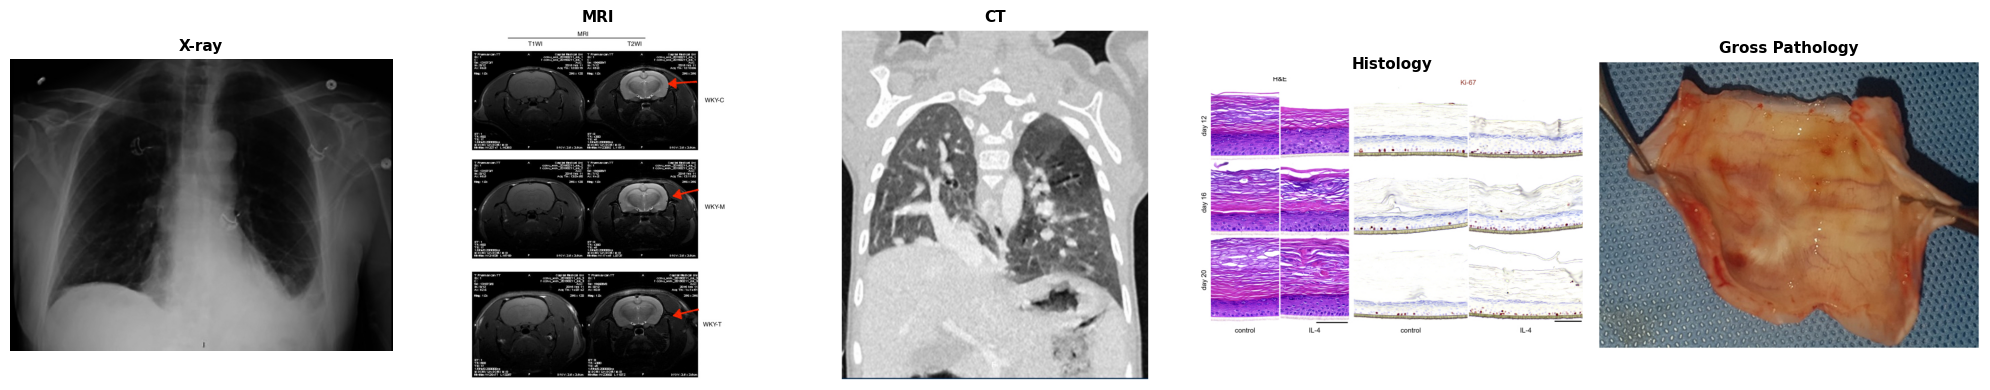

In [1]:
import json
import matplotlib.pyplot as plt
from PIL import Image
import random

domains = {
    "X-ray":          "/home/as5606/projects/Super_LlaVA_Med/dataset/x_ray/open_ended_train_and_val/val_open_ended_annotations.jsonl",
    "MRI":            "/home/as5606/projects/Super_LlaVA_Med/dataset/MRI/open_ended_train_and_val/val_open_ended_annotations.jsonl",
    "CT":             "/home/as5606/projects/Super_LlaVA_Med/dataset/CT/open_ended_train_and_val/val_open_ended_annotations.jsonl",
    "Histology":      "/home/as5606/projects/Super_LlaVA_Med/dataset/histology/open_ended_train_and_val/val_open_ended_annotations.jsonl",
    "Gross Pathology":"/home/as5606/projects/Super_LlaVA_Med/dataset/gross_pathology/open_ended_train_and_val/val_open_ended_annotations.jsonl",
}

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for ax, (name, path) in zip(axes, domains.items()):
    records = [json.loads(l) for l in open(path) if json.loads(l)["type"] == "standard"]
    rec = random.choice(records)
    img = Image.open(rec["image_path"]).convert("RGB")
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(name, fontsize=11, fontweight="bold")

plt.tight_layout()
plt.savefig("/home/as5606/projects/Super_LlaVA_Med/paper_graphs/domain_samples.pdf", bbox_inches="tight", dpi=150)
plt.show()


In [2]:
import json, os, shutil, random

domains = {
    "x_ray":          "/home/as5606/projects/Super_LlaVA_Med/dataset/x_ray/open_ended_train_and_val/val_open_ended_annotations.jsonl",
    "mri":            "/home/as5606/projects/Super_LlaVA_Med/dataset/MRI/open_ended_train_and_val/val_open_ended_annotations.jsonl",
    "ct":             "/home/as5606/projects/Super_LlaVA_Med/dataset/CT/open_ended_train_and_val/val_open_ended_annotations.jsonl",
    "histology":      "/home/as5606/projects/Super_LlaVA_Med/dataset/histology/open_ended_train_and_val/val_open_ended_annotations.jsonl",
    "gross_pathology":"/home/as5606/projects/Super_LlaVA_Med/dataset/gross_pathology/open_ended_train_and_val/val_open_ended_annotations.jsonl",
}

OUT = "/home/as5606/projects/Super_LlaVA_Med/image_download/image_download_2"
os.makedirs(OUT, exist_ok=True)

for name, path in domains.items():
    records = [json.loads(l) for l in open(path) if json.loads(l)["type"] == "standard"]
    rec = random.choice(records)
    ext = os.path.splitext(rec["image_path"])[1]
    shutil.copy(rec["image_path"], f"{OUT}/{name}{ext}")
    print(f"{name} → {rec['image_path']}")


x_ray → /shared/rc/vlm-idk/LLaVA/data/images/32551331_fig3-2333794X20928200.jpg
mri → /shared/rc/vlm-idk/LLaVA/data/images/25368795_fig11780.jpg
ct → /shared/rc/vlm-idk/LLaVA/data/images/29255682_fig1.jpg
histology → /shared/rc/vlm-idk/LLaVA/data/images/34046153_fig2-20363613211016121.jpg
gross_pathology → /shared/rc/vlm-idk/LLaVA/data/images/35154768_fig3-2050313X20967175.jpg


In [3]:
for name, path in domains.items():
    records = [json.loads(l) for l in open(path) if json.loads(l)["type"] == "standard"]
    # find the one we saved
    saved_paths = {
        "x_ray":          "/shared/rc/vlm-idk/LLaVA/data/images/32551331_fig3-2333794X20928200.jpg",
        "mri":            "/shared/rc/vlm-idk/LLaVA/data/images/25368795_fig11780.jpg",
        "ct":             "/shared/rc/vlm-idk/LLaVA/data/images/29255682_fig1.jpg",
        "histology":      "/shared/rc/vlm-idk/LLaVA/data/images/34046153_fig2-20363613211016121.jpg",
        "gross_pathology":"/shared/rc/vlm-idk/LLaVA/data/images/35154768_fig3-2050313X20967175.jpg",
    }
    rec = next((r for r in records if r["image_path"] == saved_paths[name]), None)
    if rec:
        print(f"{name}:")
        print(f"  Q: {rec['question']}")
        print(f"  A: {rec['answer'][:150]}")
        print()


x_ray:
  Q: How does the lung expansion look in the image?
  A: The lung expansion in the chest X-ray appears to be near-normal.

mri:
  Q: What is the location of the circular mass?
  A: The circular mass is located at the top of the frontal region of the brain.

ct:
  Q: What is the size of the mass?
  A: The size of the mass in the image is approximately 0.8 cm in diameter.

histology:
  Q: How are the tumor cells arranged?
  A: The tumor cells are arranged in an infiltrating pattern, forming irregular nests or scattered throughout the tissue.

gross_pathology:
  Q: What is the appearance of the tumor?
  A: The tumor appears to be firm, well-circumscribed, and grey fibrous in nature.

